<a id="1"></a>
<p style="background-color:#be6f37;font-family:newtimeroman;color:#FFF9ED;font-size:120%;text-align:center;border-radius:10px 10px;"> BUSINESS UNDERSTANDING</p>

Hunter's e-grocery is a well-known French brand based in Brittany that offers a new generation of e-grocery and lifestyle products. With a presence in ten countries, Hunter's e-grocery continually seeks new ways to anticipate and meet customer demands, building strong loyalty among its customers. However, recent black swan events such as Covid-19, the Ukraine crisis, and gas shortages have impacted purchasing behavior, making it necessary to develop a business values proposition to increase customer lifetime value. To ensure successful completion of this extensive study, we will implement a 5-step methodology.

<a id='top'></a>
<div class="list-group" id="list-tab" role="tablist">
<p style="background-color:#be6f37;font-family:newtimeroman;color:#FFF9ED;font-size:150%;text-align:center;border-radius:10px 10px;">TABLE OF CONTENTS</p>

[OVERVIEW](#0)
- [1. BUSINESS UNDERSTANDING](#1)

- [2. DATA UNDERSTANDING](#2)

    - [2.1 Get information on the data](#2.1)
    - [2.2 Conducting summary statistics](#2.2)
    - [2.3 Taking care of Null values](#2.3)
    - [2.4 Converting data types](#2.4)
- [3. DATA PREPARATION](#3)
    - [3.1 Investigating all elements within each feature](#3.1)
    - [3.2 Aggregating & grouping values to visualize purchasing behaviour](#3.2)
    - [3.3 Creating time based features](#3.3)
    - [3.4  Heatmap Study](#3.4)
    - [3.5  Visualizing order time period](#3.5)
    - [3.6 Creating order group feature](#3.6)
    - [3.7 Visualizing order group feature](#3.7)
    - [3.8 Visualizing top 10 products](#3.8)
    - [3.9 Visualizing bottom 10 products](#3.9)
    - [3.9 Aggregating & grouping values to understand purchasing behaviour](#3.10)
    - [3.10 Aggregating & grouping values to understand product reordered ratio](#3.11)
    - [3.11 Aggregating & grouping values to visualize reordered ratio](#3.12)

- [4. MODELING](#4)

    - [4.1 Preparing & building apriori algorithm](#4.1)
    - [4.2 Building customized plot parameters](#4.2)
    - [4.3 Building the frequent occurrence iteams](#4.3)
    - [4.4 Adding Iteam sets count to the frequent items list](#4.4)

- [5. EVALUATION](#5)
    - [5.1 Review of the current model](#5.1)
    - [5.2 Rule metrics: as built vs order-level baskets](#5.2)
    - [5.3 Holdout validation against a popularity baseline](#5.3)
- [6. CONCLUSION](#6)

In [55]:
# IMPORTING PACKAGES
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.graph_objs as go
import plotly.io as pio
import seaborn as sns
from datetime import datetime
import sklearn
import plotly.express as px
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules
from sklearn.cluster import KMeans , k_means
from IPython.display import Image, display, HTML
import warnings
warnings.filterwarnings('ignore')

In [4]:
main_data= pd.read_csv("ECommerce_consumer behaviour.csv")
df = main_data.copy()
df

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_id,add_to_cart_order,reordered,department_id,department,product_name
0,2425083,49125,1,2.0,18.0,NaN,17.0,1.0,0.0,13.0,pantry,baking ingredients
1,2425083,49125,1,2.0,18.0,NaN,91.0,2.0,0.0,16.0,dairy eggs,soy lactosefree
2,2425083,49125,1,2.0,18.0,NaN,36.0,3.0,0.0,16.0,dairy eggs,butter
3,2425083,49125,1,2.0,18.0,NaN,83.0,4.0,0.0,4.0,produce,fresh vegetables
4,2425083,49125,1,2.0,18.0,NaN,83.0,5.0,0.0,4.0,produce,fresh vegetables
...,...,...,...,...,...,...,...,...,...,...,...,...
209091,3182285,191443,65,1.0,23.0,3.0,67.0,1.0,1.0,20.0,deli,fresh dips tapenades
209092,3182285,191443,65,1.0,23.0,3.0,24.0,2.0,1.0,4.0,produce,fresh fruits
209093,3182285,191443,65,1.0,23.0,3.0,83.0,3.0,1.0,4.0,produce,fresh vegetables
209094,3182285,191443,65,1.0,23.0,3.0,86.0,4.0,1.0,16.0,dairy eggs,eggs


<a id="2"></a>  
<p style="background-color:#be6f37;font-family:newtimeroman;color:#FFF9ED;font-size:120%;text-align:center;border-radius:10px 10px;"> DATA UNDERSTANDING</p>

#### **The dataset consists of 2019501 Rows & 12 Columns which are as follows :**

- order_id – (A unique number to identity the order)
- user_id - (A unique number to identify the user)
- order_number – (Number of the order)
- order_dow – (Day of the Week the order was made)
- order_hour_of_day – (Time of the order)
- days_since_prior_order - (History of the order)
- product_id – (Id of the product)
- add_to_cart_order – (Number of items added to cart)
- reordered – (If the reorder took place)
- department_id - (Unique number allocated to each department)
- department – (Names of the departments)
- product_name – (Name of the products)

<a id="2.1"></a>
## <b>2.1<span style='color:#be6f37'> Get information on the data</span></b>

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 209096 entries, 0 to 209095
Data columns (total 12 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                209096 non-null  int64  
 1   user_id                 209096 non-null  int64  
 2   order_number            209096 non-null  int64  
 3   order_dow               209095 non-null  float64
 4   order_hour_of_day       209095 non-null  float64
 5   days_since_prior_order  195342 non-null  float64
 6   product_id              209095 non-null  float64
 7   add_to_cart_order       209095 non-null  float64
 8   reordered               209095 non-null  float64
 9   department_id           209095 non-null  float64
 10  department              209095 non-null  object 
 11  product_name            209095 non-null  object 
dtypes: float64(7), int64(3), object(2)
memory usage: 19.1+ MB


<a id="2.2"></a>
## <b>2.2 <span style='color:#be6f37'> Conducting summary statistics</span></b>

In [6]:
df.isnull().sum()

,0
order_id,0
user_id,0
order_number,0
order_dow,1
order_hour_of_day,1
days_since_prior_order,13754
product_id,1
add_to_cart_order,1
reordered,1
department_id,1


#### <b><span style='color:#FF0000'> NOTE :</span></b>

**From the above summary statistics we could see that we have null value in “ days_since_prior_order” which is 6.8 % of the entire data set. The following are the steps we will do to further continue on the explanatory analysis in sequential order.**

In [7]:
df['days_since_prior_order'].unique()

array([nan,  3.,  6.,  7., 30., 20.,  4.,  8., 15., 10., 28.,  9., 12.,
       11.,  2., 25., 13., 29., 14., 21.,  5.,  1., 18.,  0., 19., 17.,
       22., 26., 24., 16., 23., 27.])

<a id="2.3"></a>
## <b>2.3 <span style='color:#be6f37'> Taking care of Null values</span></b>

In [8]:
# TAKING CARE OF NULL VALUES
for col in df.columns:
    if df[col].dtypes == 'float64':
        df[col].fillna(-1,inplace=True)

In [9]:
df.isnull().sum()

,0
order_id,0
user_id,0
order_number,0
order_dow,0
order_hour_of_day,0
days_since_prior_order,0
product_id,0
add_to_cart_order,0
reordered,0
department_id,0


In [10]:
df.isnull().sum()

,0
order_id,0
user_id,0
order_number,0
order_dow,0
order_hour_of_day,0
days_since_prior_order,0
product_id,0
add_to_cart_order,0
reordered,0
department_id,0


<a id="2.4"></a>
## <b>2.4 <span style='color:#be6f37'> Converting data types</span></b>

In [11]:
# CONVERTING DATA TYPES
df['days_since_prior_order']= df['days_since_prior_order'].astype(np.int64)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 209096 entries, 0 to 209095
Data columns (total 12 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                209096 non-null  int64  
 1   user_id                 209096 non-null  int64  
 2   order_number            209096 non-null  int64  
 3   order_dow               209096 non-null  float64
 4   order_hour_of_day       209096 non-null  float64
 5   days_since_prior_order  209096 non-null  int64  
 6   product_id              209096 non-null  float64
 7   add_to_cart_order       209096 non-null  float64
 8   reordered               209096 non-null  float64
 9   department_id           209096 non-null  float64
 10  department              209095 non-null  object 
 11  product_name            209095 non-null  object 
dtypes: float64(6), int64(4), object(2)
memory usage: 19.1+ MB


<a id="3"></a>
<p style="background-color:#be6f37;font-family:newtimeroman;color:#FFF9ED;font-size:120%;text-align:center;border-radius:10px 10px;"> DATA PREPARATION</p>

<a id="3.1"></a>
## <b>3.1 <span style='color:#be6f37'> Investigating all elements within each feature</span></b>

In [13]:
for colum in df:
    # Cast to string if column contains objects to avoid mixed-type sorting issues (e.g. string and float/nan)
    if df[colum].dtype == 'object':
        unique_values = np.unique(df[colum].astype(str))
    else:
        unique_values = np.unique(df[colum])

    nr_values = len(unique_values)
    if nr_values < 22:
        print("The number of unique values for features {} : {} --- {}".format(colum, nr_values, unique_values))
    else:
         print("The number of unique values for features {} : {}".format(colum, nr_values))

The number of unique values for features order_id : 20550
The number of unique values for features user_id : 18720
The number of unique values for features order_number : 100
The number of unique values for features order_dow : 8 --- [-1.  0.  1.  2.  3.  4.  5.  6.]
The number of unique values for features order_hour_of_day : 25
The number of unique values for features days_since_prior_order : 32
The number of unique values for features product_id : 135
The number of unique values for features add_to_cart_order : 94
The number of unique values for features reordered : 3 --- [-1.  0.  1.]
The number of unique values for features department_id : 22
The number of unique values for features department : 22
The number of unique values for features product_name : 135


<a id="3.2"></a>
## <b>3.2 <span style='color:#be6f37'> Aggregating & grouping values to visualize purchasing behaviour</span></b>

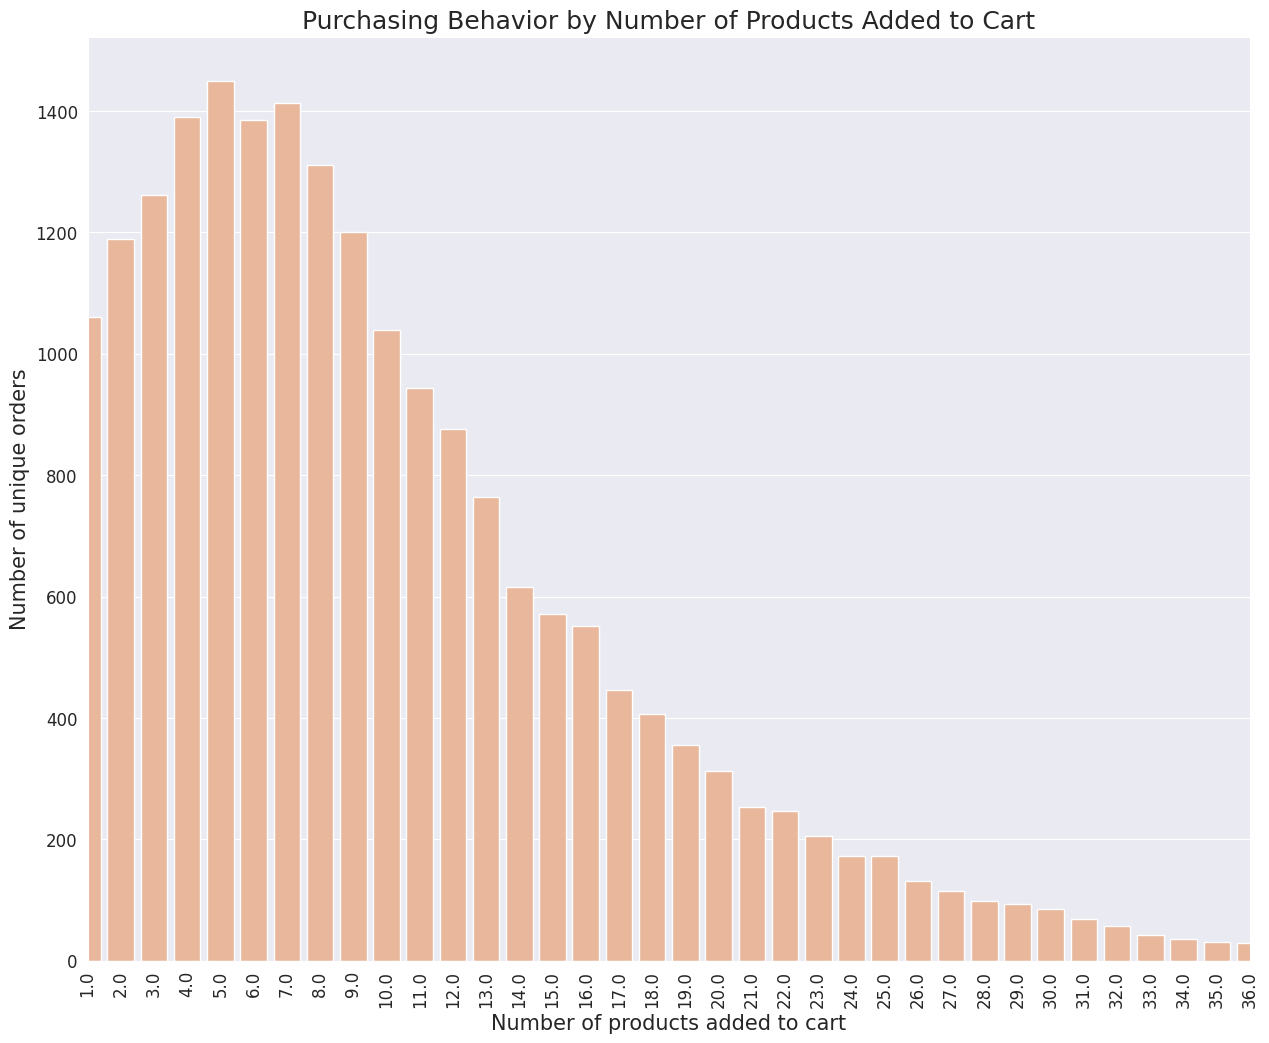

In [14]:
# AGGREGATING & GROUPING VALUES TO VISUALIZE PURCHASING BEHAVIOUR
grouped = df.groupby("order_id")["add_to_cart_order"].aggregate("max").reset_index()
grouped = grouped.add_to_cart_order.value_counts()

sns.set_style('dark')
sns.set_palette("rocket_r")
f, ax = plt.subplots(figsize=(15, 12))
sns.barplot(x=grouped.index, y=grouped.values, ax=ax)
ax.grid(True, axis='y')
plt.xticks(rotation='vertical', fontsize=12)
plt.yticks(fontsize=12)
plt.ylabel('Number of unique orders', fontsize=15)
plt.xlabel('Number of products added to cart', fontsize=15)
plt.title('Purchasing Behavior by Number of Products Added to Cart', fontsize=18)
plt.xlim(0, 35)  # limit the X axis values to 35
plt.show()

#### <b><span style='color:#FF0000'> NOTE :</span></b>
**From the above plot we can understand the purchasing behavior of the customers, where we could observe that customers are usually ordering on average around 4-7 products.**

<a id="3.3"></a>
## <b>3.3 <span style='color:#be6f37'> Creating time based features</span></b>

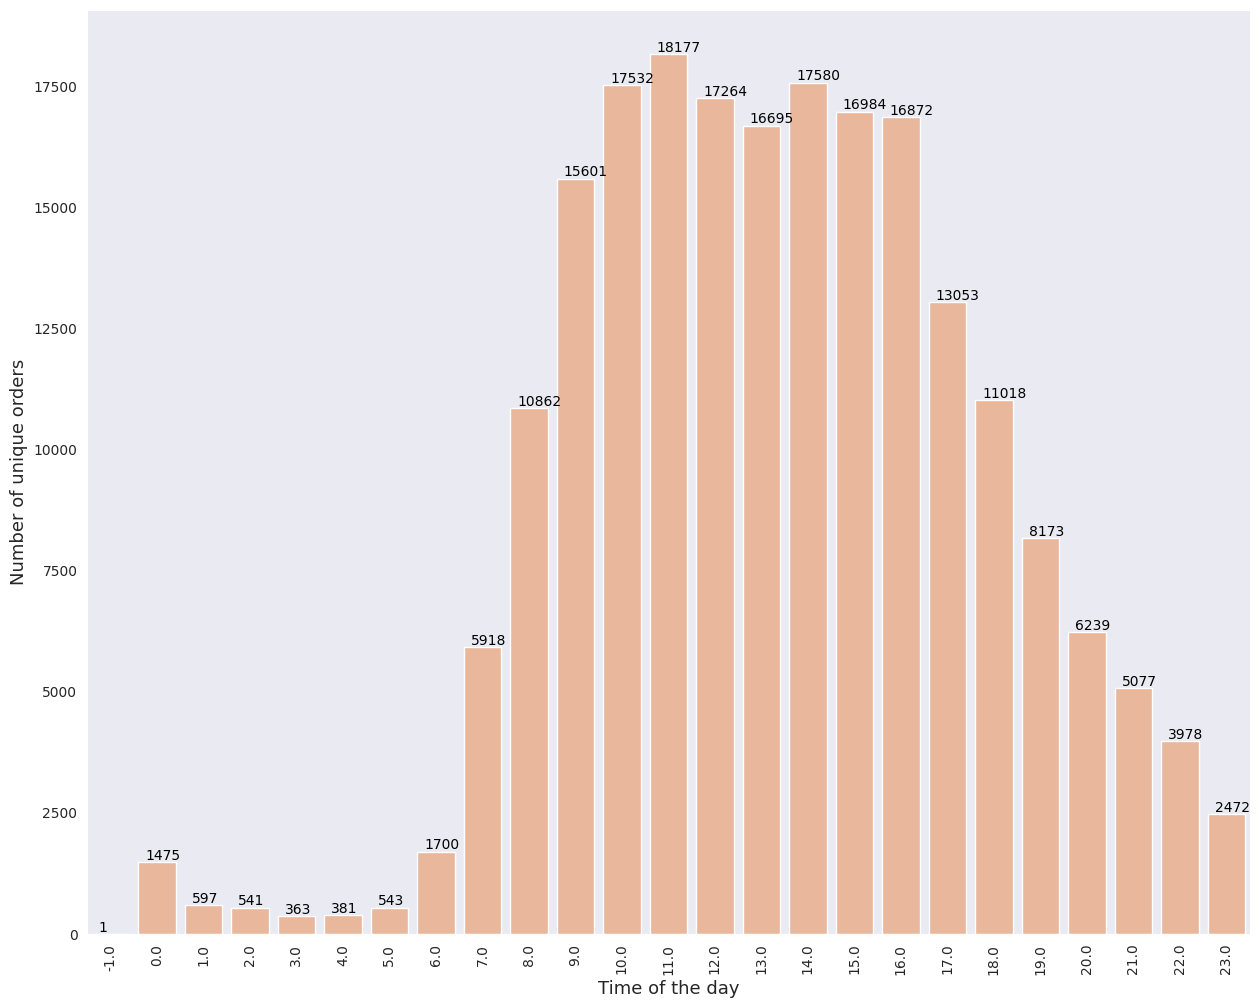

In [15]:
# TIME OF THE DAY WHEN THE ORDER WAS MADE
grouped = df.groupby('order_hour_of_day', as_index=True).agg({'user_id':'count'}).sort_values(by='user_id',ascending=False)


f, ax = plt.subplots(figsize=(15, 12))
plt.xticks(rotation='vertical')
sns.barplot(x = grouped.index, y = grouped.user_id)
sns.color_palette("rocket_r", 10)

plt.ylabel('Number of unique orders', fontsize=13)
plt.xlabel('Time of the day', fontsize=13)

for i in ax.patches:
    ax.text(i.get_x()+0.15, i.get_height()+50, str(round(i.get_height())), fontsize=10, color='black')
plt.show()

plt.show()

#### <b><span style='color:#FF0000'> NOTE :</span></b>
**From the above plot we can understand a trend where majority of customers ordered between 10 AM - 4 PM**

<a id="3.4"></a>
## <b>3.4 <span style='color:#be6f37'> Heatmap Study</span></b>

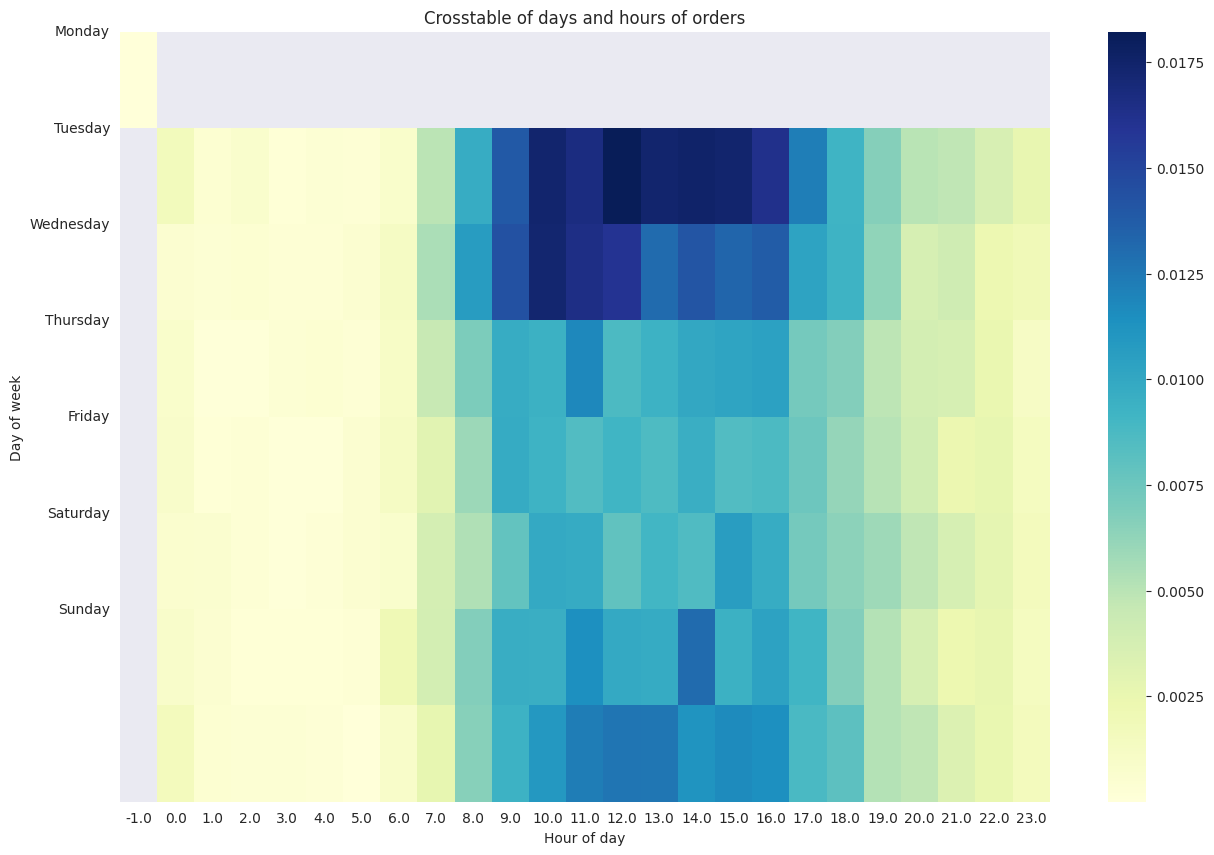

In [16]:
day_hour_df = df.groupby(["order_dow", "order_hour_of_day"])["order_number"].aggregate("count").reset_index()
day_hour_df_piv = day_hour_df.pivot(index='order_dow', columns='order_hour_of_day', values='order_number')/df.shape[0]

plt.figure(figsize=(15,10))
sns.heatmap(day_hour_df_piv, cmap='YlGnBu')
plt.yticks([0,1, 2, 3, 4, 5, 6],["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
plt.xlabel("Hour of day")
plt.yticks(rotation=0)
plt.ylabel("Day of week")

plt.title("Crosstable of days and hours of orders");

#### <b><span style='color:#FF0000'> NOTE :</span></b>
**As we continue to explore further we can observe interesting trends which are as follows:**
- **The peak traffic is on a Monday between 10 AM  - 16 PM which is the beginning of the week**
- **The low periods happen to be during the mid-week from Wednesday - Friday From 4 PM onwards**

In [17]:
def order_time(x):
    return f'{"morning" if x in range(6, 12) else "afternoon" if x in range(12, 18) else "evening" if x in range(18, 23) else "night"}'


In [18]:
df['order_time_period'] = df['order_hour_of_day'].apply(order_time)
df

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_id,add_to_cart_order,reordered,department_id,department,product_name,order_time_period
0,2425083,49125,1,2.0,18.0,-1,17.0,1.0,0.0,13.0,pantry,baking ingredients,evening
1,2425083,49125,1,2.0,18.0,-1,91.0,2.0,0.0,16.0,dairy eggs,soy lactosefree,evening
2,2425083,49125,1,2.0,18.0,-1,36.0,3.0,0.0,16.0,dairy eggs,butter,evening
3,2425083,49125,1,2.0,18.0,-1,83.0,4.0,0.0,4.0,produce,fresh vegetables,evening
4,2425083,49125,1,2.0,18.0,-1,83.0,5.0,0.0,4.0,produce,fresh vegetables,evening
...,...,...,...,...,...,...,...,...,...,...,...,...,...
209091,3182285,191443,65,1.0,23.0,3,67.0,1.0,1.0,20.0,deli,fresh dips tapenades,night
209092,3182285,191443,65,1.0,23.0,3,24.0,2.0,1.0,4.0,produce,fresh fruits,night
209093,3182285,191443,65,1.0,23.0,3,83.0,3.0,1.0,4.0,produce,fresh vegetables,night
209094,3182285,191443,65,1.0,23.0,3,86.0,4.0,1.0,16.0,dairy eggs,eggs,night


In [19]:
df.pivot_table(index='order_dow',columns='order_time_period',values='user_id',aggfunc=['count'])

count                         
order_time_period afternoon evening  morning   night
order_dow                                           
-1.0                    NaN     NaN      NaN     1.0
 0.0                20720.0  6134.0  13268.0  1335.0
 1.0                16857.0  5354.0  13713.0   933.0
 2.0                11695.0  4522.0   9081.0   731.0
 3.0                10900.0  4257.0   7899.0   745.0
 4.0                11112.0  4941.0   7840.0   852.0
 5.0                12890.0  4281.0   9052.0   772.0
 6.0                14274.0  4996.0   8937.0  1004.0

<a id="3.5"></a>
## <b>3.5 <span style='color:#be6f37'> Visualizing order time period</span></b>

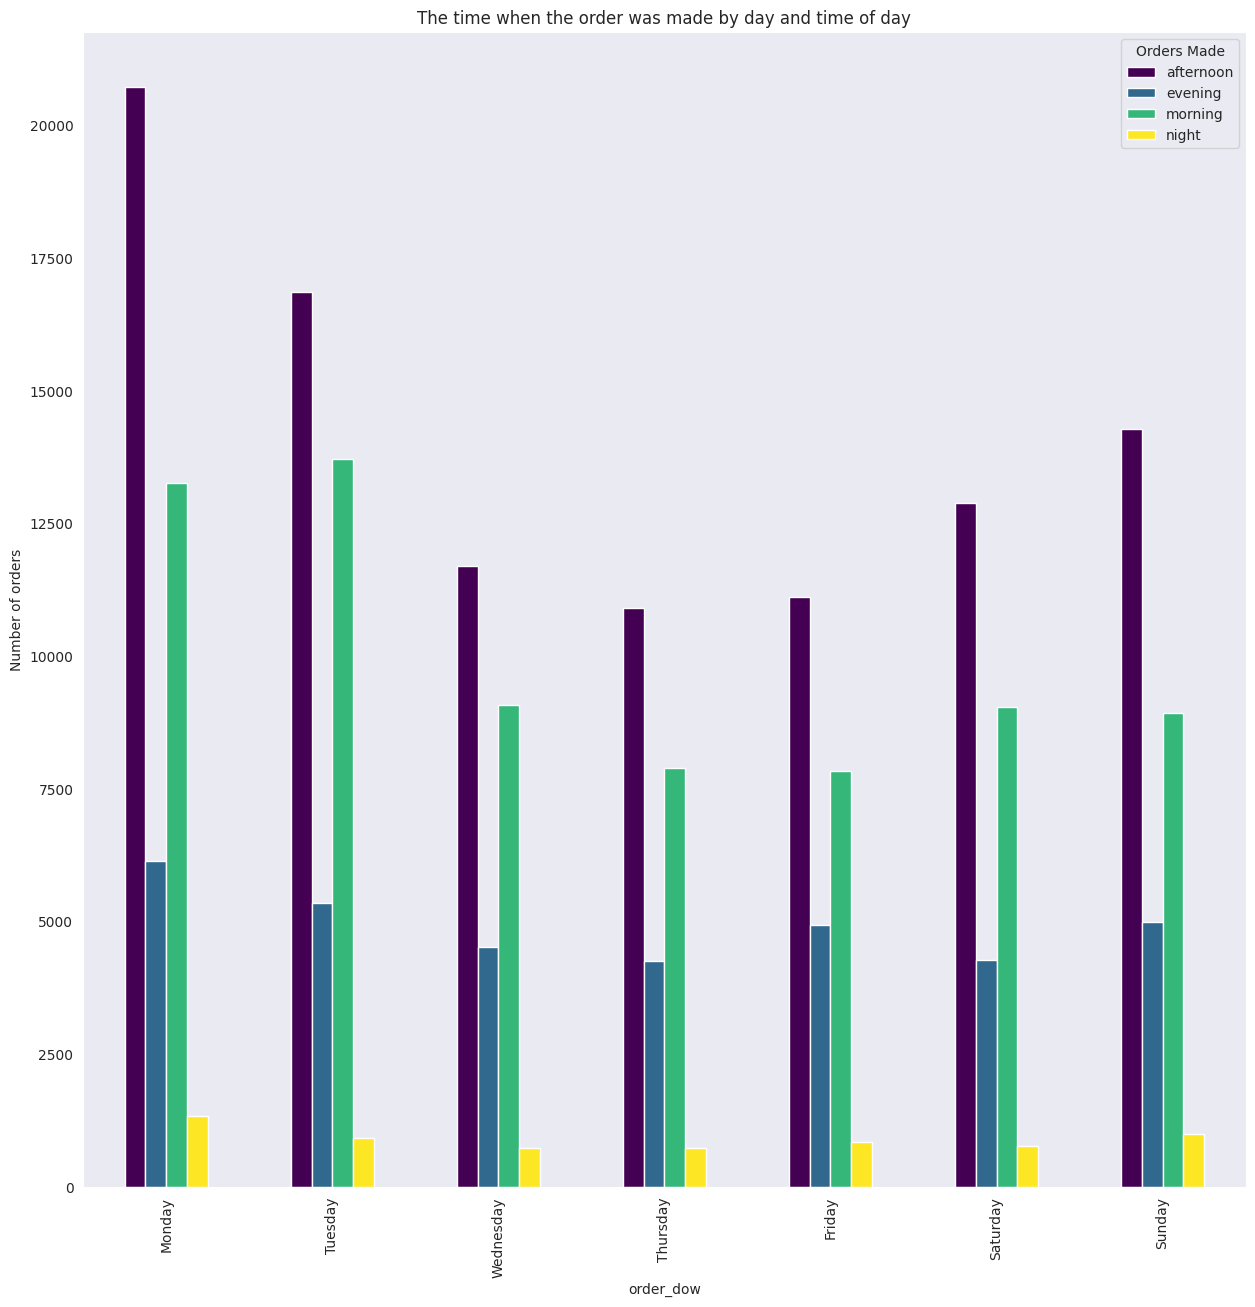

In [22]:
# Define the color palette
color_palette = plt.get_cmap('viridis')

# Generate the plot, filtering out the '-1.0' placeholder row
orders_by_day_time = df.pivot_table(
    index='order_dow',
    columns='order_time_period',
    values='user_id',
    aggfunc='count'
)

# Drop the -1.0 row if present to keep only Monday through Sunday
if -1.0 in orders_by_day_time.index:
    orders_by_day_time = orders_by_day_time.drop(index=-1.0)

ax = orders_by_day_time.plot(kind='bar', figsize=(15, 15), color=color_palette(np.linspace(0, 1, len(orders_by_day_time.columns))))
ax.set_title('The time when the order was made by day and time of day')
ax.set_xticklabels(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]) # fixed the x-axis labels
ax.set_ylabel('Number of orders')
ax.legend(title='Orders Made', bbox_to_anchor=(1.0, 1.0))
plt.show()

#### <b><span style='color:#FF0000'> NOTE :</span></b>
**The above plot again give us a global overview where we can observe trends:**
- **Where most customers prefer to order between morning and early afternoon**
- **Relatively quiet few customers order during evenig and night**

<a id="3.6"></a>
## <b>3.6 <span style='color:#be6f37'> Creating order group feature</span></b>

In [23]:
def order_number_group(num_orders):
    ranges = [(1, 10), (11, 20), (21, 30), (31, 40), (41, 50),(51, 60),(61, 70),(71, 80),(81, 90),(91, 100)]
    for r in ranges:
        if num_orders in range(r[0], r[1]+1):
            return f"{r[0]}-{r[1]} orders"
    return "More than 100 orders"

In [24]:
df['order_number_group']=df['order_number'].apply(order_number_group)
df

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_id,add_to_cart_order,reordered,department_id,department,product_name,order_time_period,order_number_group
0,2425083,49125,1,2.0,18.0,-1,17.0,1.0,0.0,13.0,pantry,baking ingredients,evening,1-10 orders
1,2425083,49125,1,2.0,18.0,-1,91.0,2.0,0.0,16.0,dairy eggs,soy lactosefree,evening,1-10 orders
2,2425083,49125,1,2.0,18.0,-1,36.0,3.0,0.0,16.0,dairy eggs,butter,evening,1-10 orders
3,2425083,49125,1,2.0,18.0,-1,83.0,4.0,0.0,4.0,produce,fresh vegetables,evening,1-10 orders
4,2425083,49125,1,2.0,18.0,-1,83.0,5.0,0.0,4.0,produce,fresh vegetables,evening,1-10 orders
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
209091,3182285,191443,65,1.0,23.0,3,67.0,1.0,1.0,20.0,deli,fresh dips tapenades,night,61-70 orders
209092,3182285,191443,65,1.0,23.0,3,24.0,2.0,1.0,4.0,produce,fresh fruits,night,61-70 orders
209093,3182285,191443,65,1.0,23.0,3,83.0,3.0,1.0,4.0,produce,fresh vegetables,night,61-70 orders
209094,3182285,191443,65,1.0,23.0,3,86.0,4.0,1.0,16.0,dairy eggs,eggs,night,61-70 orders


<a id="3.7"></a>
## <b>3.7 <span style='color:#be6f37'> Visualizing order group feature</span></b>

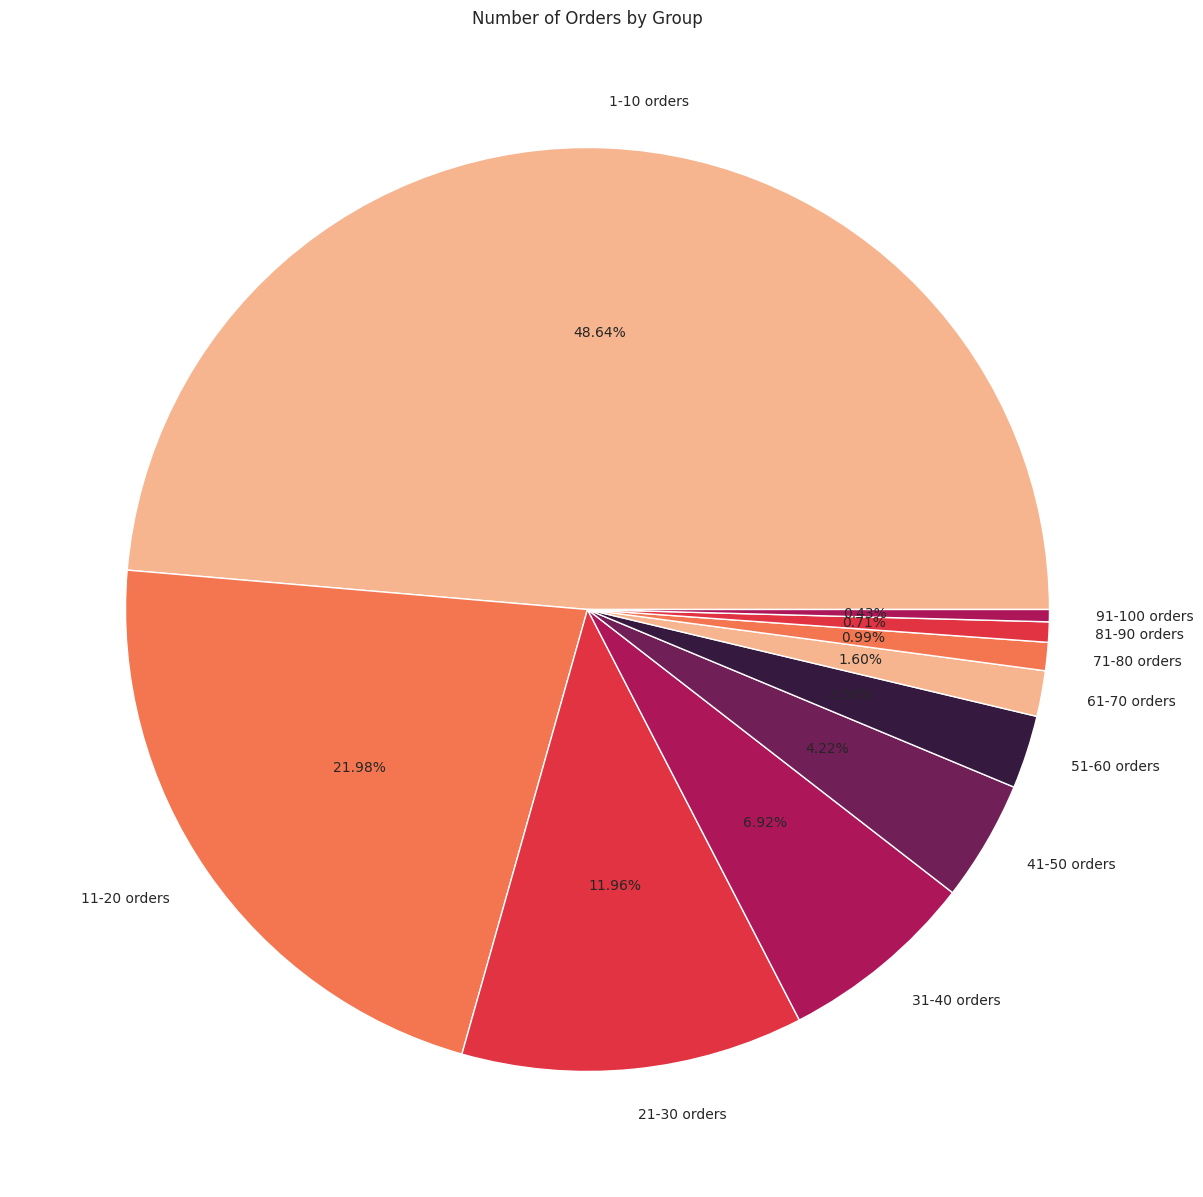

In [25]:
orders_by_group = df.groupby('order_number_group')['user_id'].count().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(15, 15))
ax.set_facecolor('lightgray')

orders_by_group.plot(kind='pie', autopct='%1.2f%%', title='Number of Orders by Group', ax=ax)
ax.set_ylabel('')

plt.show()

#### <b><span style='color:#FF0000'> NOTE :</span></b>
**The above pie chart give us a global overview of market basket analysis trend:**
- **Out of all the products, approximately 49% were purchased from the category 1-10 group**

<a id="3.8"></a>
## <b>3.8 <span style='color:#be6f37'> Visualizing top 10 products</span></b>

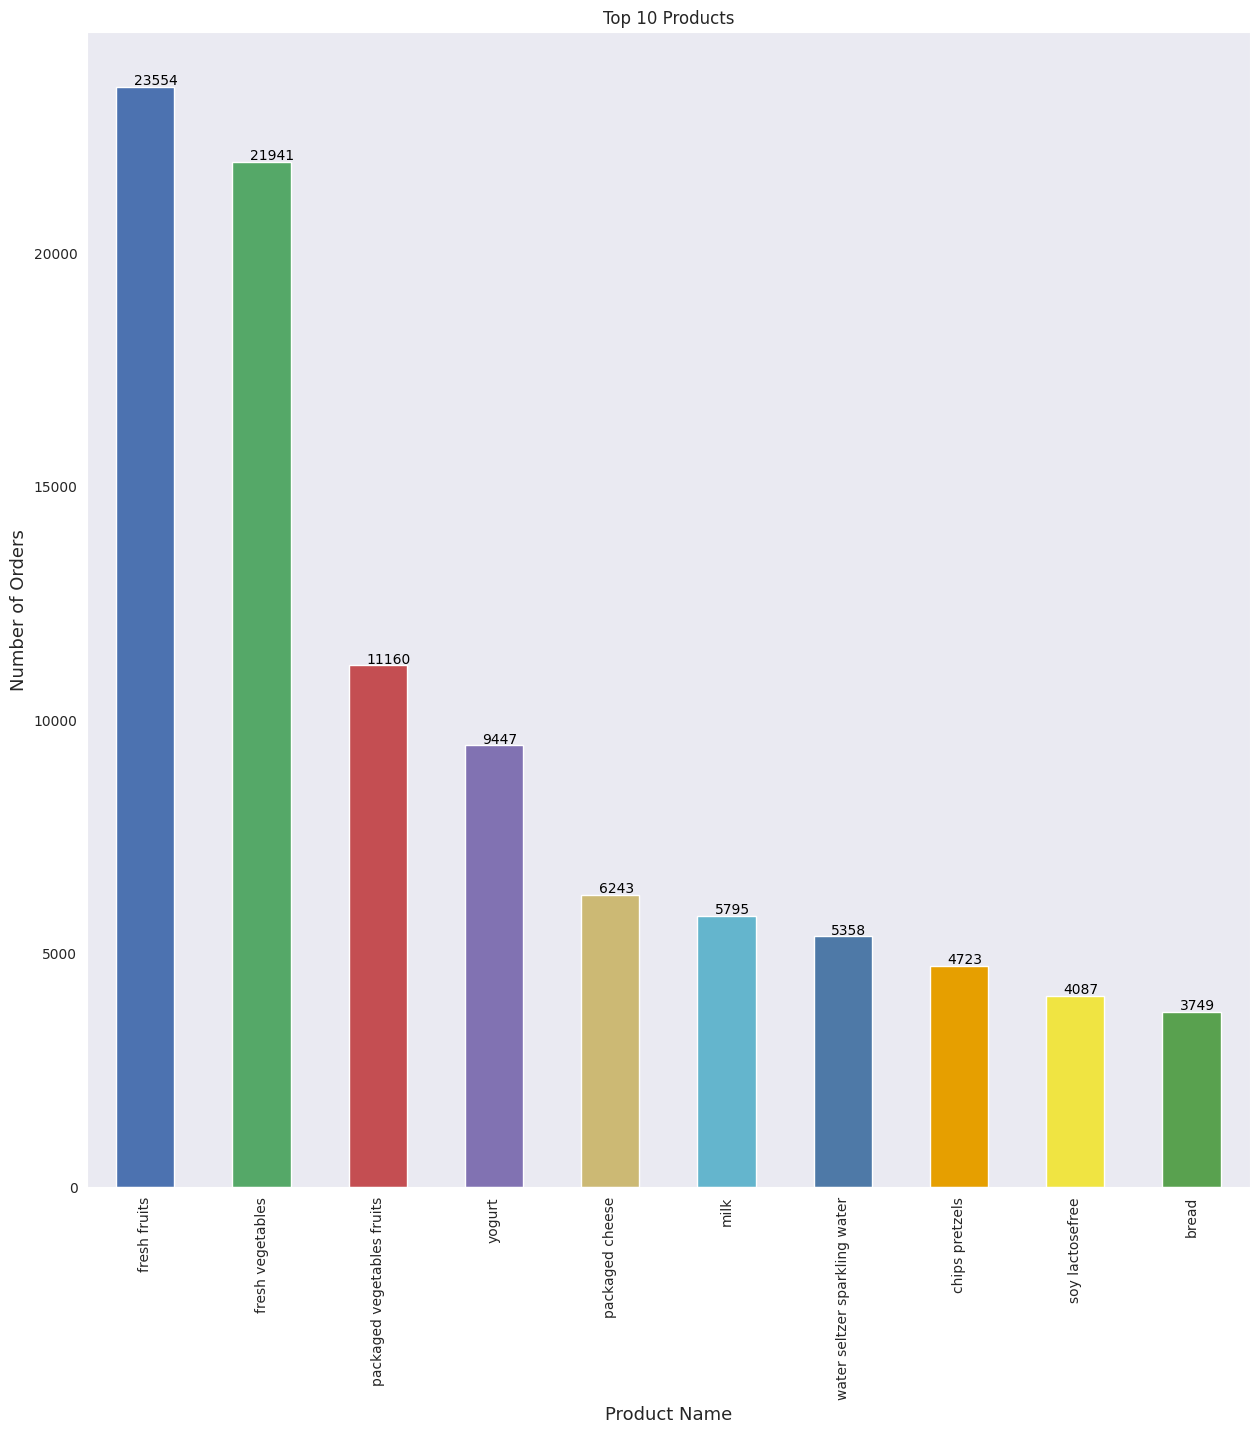

In [26]:
top_products = df.groupby('product_name')['user_id'].count().sort_values(ascending=False).head(10)
colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974', '#64B5CD', '#4E79A7', '#E69F00', '#F0E442', '#59A14F', '#8C8C8C', '#9C755F', '#EDB8A7', '#BDBDBD', '#000000']
ax = top_products.plot(kind='bar', title='Top 10 Products', color=colors, figsize=(15, 15))
plt.xlabel('Product Name',fontsize=13)
plt.ylabel('Number of Orders',fontsize=13)
for i in ax.patches:
    ax.text(i.get_x()+0.15, i.get_height()+50, str(round(i.get_height())), fontsize=10, color='black')
plt.show()

<a id="3.9"></a>
## <b>3.9 <span style='color:#be6f37'> Visualizing bottom 10 products</span></b>

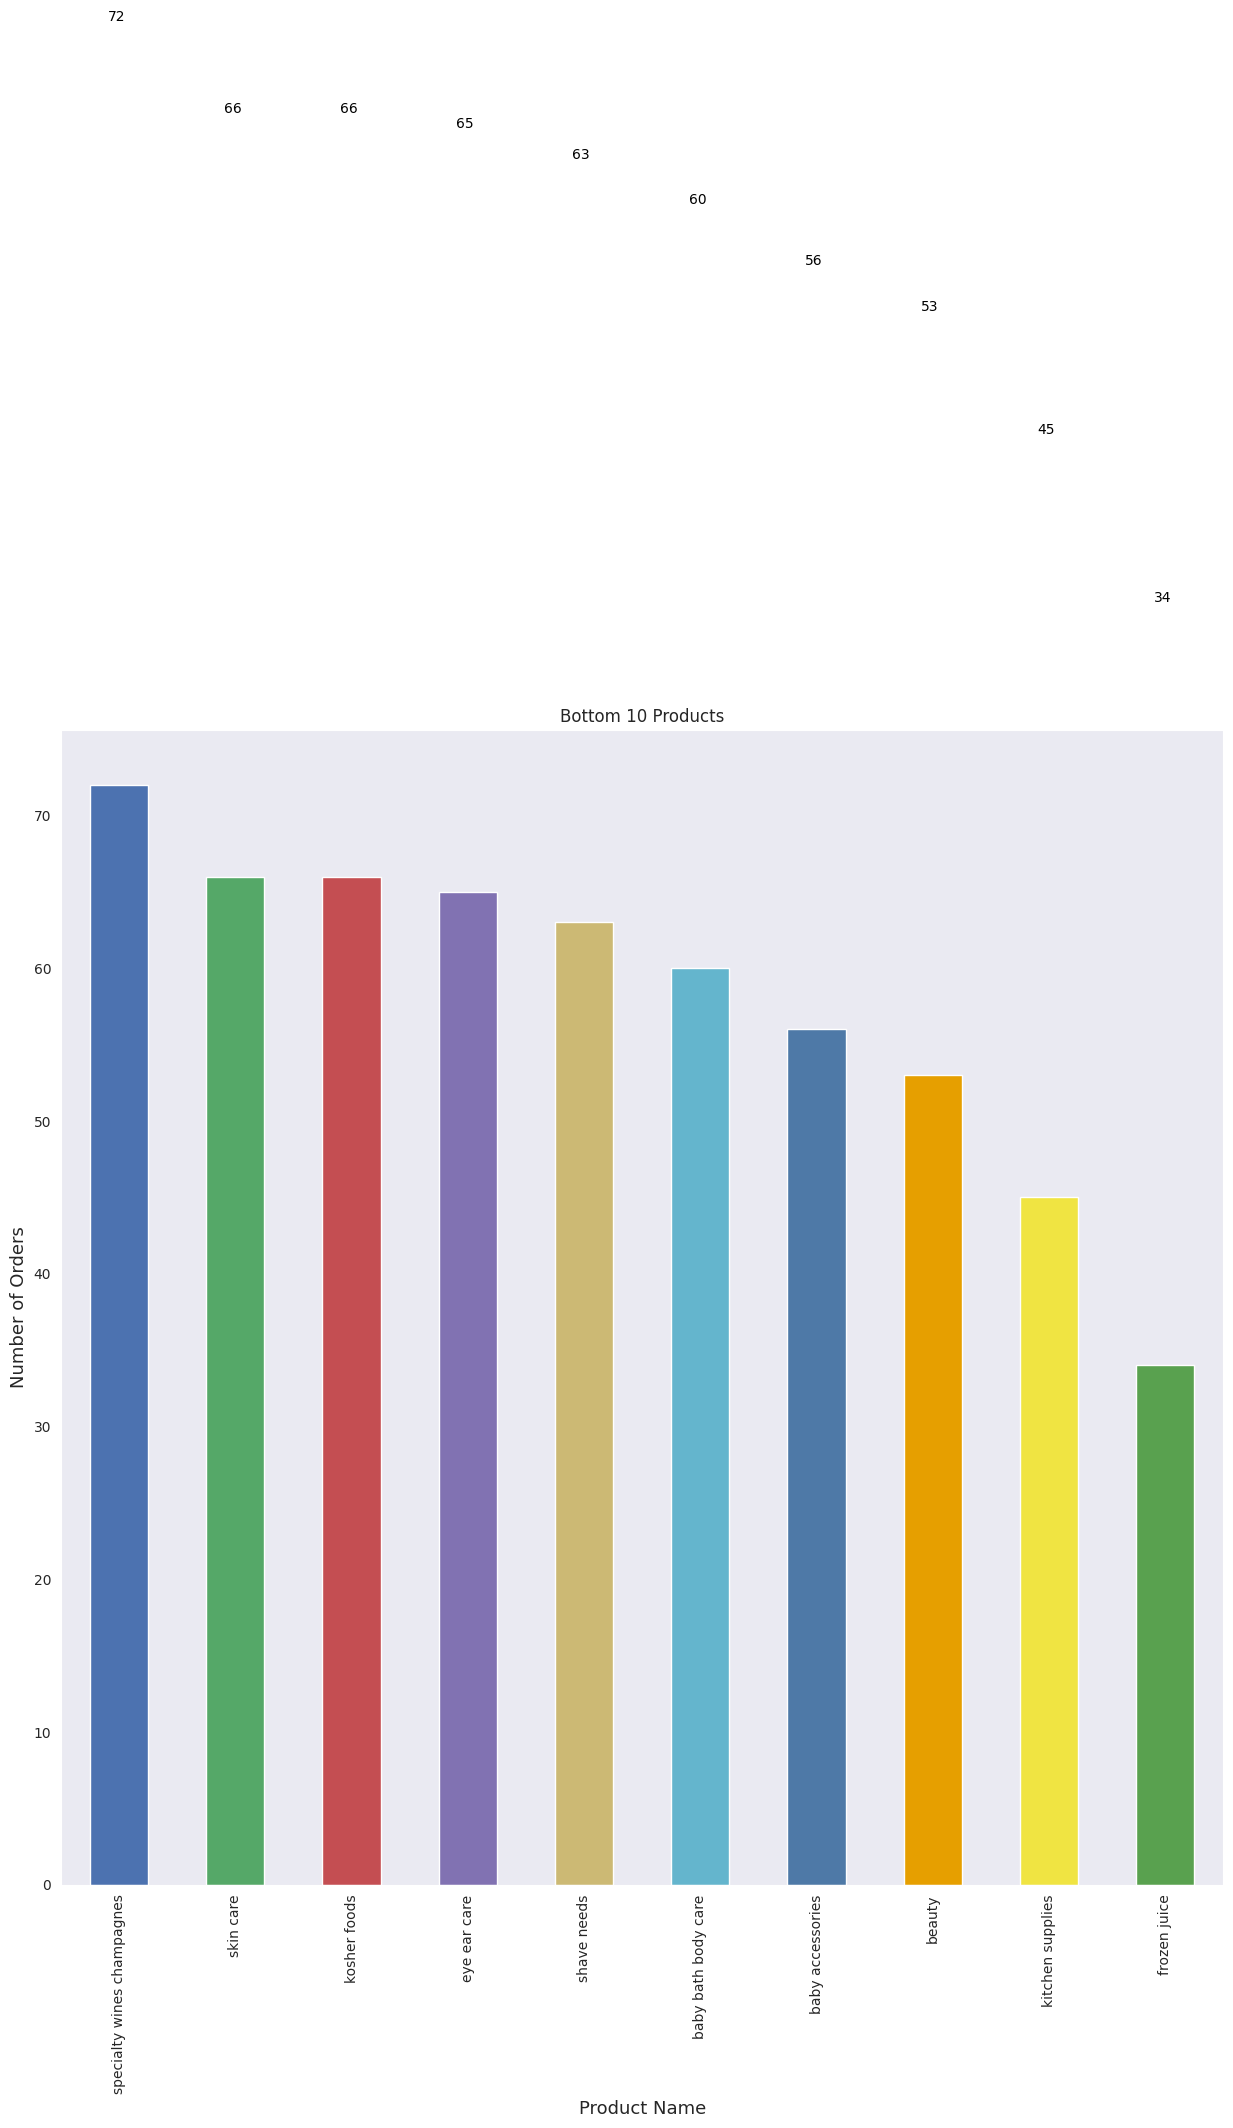

In [27]:
bottom_products = df.groupby('product_name')['user_id'].count().sort_values(ascending=False).tail(10)
colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974', '#64B5CD', '#4E79A7', '#E69F00', '#F0E442', '#59A14F', '#8C8C8C', '#9C755F', '#EDB8A7', '#BDBDBD', '#000000']
ax = bottom_products.plot(kind='bar', title='Bottom 10 Products', color=colors, figsize=(15, 15))
plt.xlabel('Product Name',fontsize=13)
plt.ylabel('Number of Orders',fontsize=13)
for i in ax.patches:
    ax.text(i.get_x()+0.15, i.get_height()+50, str(round(i.get_height())), fontsize=10, color='black')
plt.show()

<a id="3.10"></a>
## <b>3.10 <span style='color:#be6f37'> Aggregating & grouping values to understand purchasing behaviour</span></b>

In [28]:
# AGGREGATING & GROUPING VALUES TO UNDERSTAND PURCHASING BEHAVIOUR
grouped = df.groupby(["product_id","product_name","department","order_time_period"])["reordered"].aggregate('count').reset_index()
grouped = grouped.sort_values(by='reordered', ascending=False)[:15].reset_index()
del grouped["index"]
grouped

,product_id,product_name,department,order_time_period,reordered
0,24.0,fresh fruits,produce,afternoon,10881
1,83.0,fresh vegetables,produce,afternoon,10478
2,24.0,fresh fruits,produce,morning,8166
3,83.0,fresh vegetables,produce,morning,7174
4,123.0,packaged vegetables fruits,produce,afternoon,5293
5,120.0,yogurt,dairy eggs,afternoon,4317
6,24.0,fresh fruits,produce,evening,3787
7,123.0,packaged vegetables fruits,produce,morning,3658
8,83.0,fresh vegetables,produce,evening,3608
9,120.0,yogurt,dairy eggs,morning,3235


#### <b><span style='color:#FF0000'> NOTE :</span></b>
**From the above table we can clearly observe that produce, dairy products, beverages and snacks are the top categories the
customers are most interested to purchase**

<a id="3.11"></a>
## <b>3.11 <span style='color:#be6f37'> Aggregating & grouping values to understand product reordered ratio</span></b>

In [29]:
# AGGREGATING & GROUPING VALUES TO UNDERSTAND PRODUCT REORDERED RATIO
grouped = df.groupby("reordered")["product_id"].aggregate('count').reset_index()
grouped['Ratio'] = grouped["product_id"].apply(lambda x: x /grouped['product_id'].sum())
grouped

,reordered,product_id,Ratio
0,-1.0,1,0.000005
1,0.0,86609,0.414207
2,1.0,122486,0.585788


<a id="3.12"></a>
## <b>3.12 <span style='color:#be6f37'> Aggregating & grouping values to visualize reordered ratio</span></b>

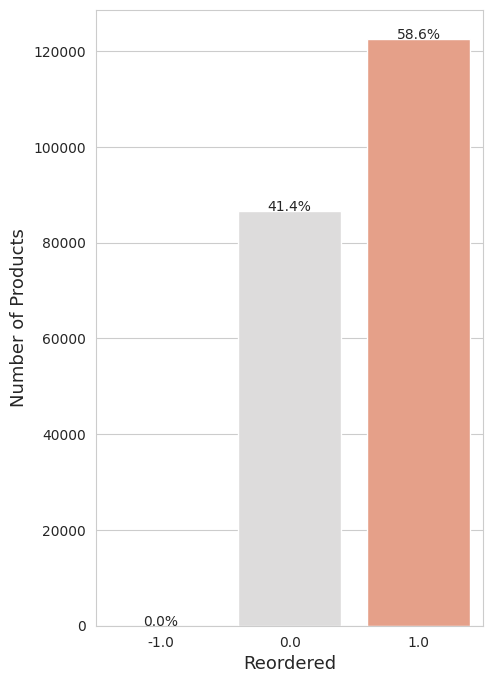

In [30]:
grouped = grouped.groupby(['reordered']).sum()['product_id'].sort_values(ascending=True)

sns.set_style('whitegrid')
f, ax = plt.subplots(figsize=(5, 8))
sns.barplot(x=grouped.index, y=grouped.values, palette='coolwarm')

grouped_pct = grouped/grouped.sum() * 100
for i, v in enumerate(grouped.values):
    ax.text(i, v+3, f'{grouped_pct.values[i]:.1f}%', ha='center', fontsize=10)

plt.ylabel('Number of Products', fontsize=13)
plt.xlabel('Reordered', fontsize=13)
plt.ticklabel_format(style='plain', axis='y')
plt.show()

#### <b><span style='color:#FF0000'> NOTE :</span></b>
**From the above we can see that 59 % of products were reordered by customers.**

<a id="4"></a>
<p style="background-color:#be6f37;font-family:newtimeroman;color:#FFF9ED;font-size:120%;text-align:center;border-radius:10px 10px;"> MODELING</p>

<a id="4.1"></a>
## <b> 4.1 <span style='color:#be6f37'> Apriori algorithm </span></b>


The Apriori algorithm is a popular algorithm used in data mining to find frequent itemsets in a dataset. It works by scanning the dataset to identify commonly occurring items, and then uses this information to generate rules about which items tend to appear together. The algorithm has two main steps:

1. The first step involves identifying all itemsets that meet a specified minimum support threshold (i.e., the minimum number of occurrences required for an itemset to be considered frequent). This is known as the "frequent itemset generation" step.
2.The second step involves using the frequent itemsets generated in step one to generate association rules, which are rules that describe the relationships between different items in the dataset. These rules can be used to predict which items are likely to be purchased together, or to identify which items are commonly associated with one another.

**Additionally Apriori algorithm is widely used in retail and e-commerce industries for market basket analysis, which involves analyzing customer purchase patterns to identify which items are frequently purchased together.**



In [31]:
pd.set_option('display.max_colwidth', None)

In [32]:
df

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_id,add_to_cart_order,reordered,department_id,department,product_name,order_time_period,order_number_group
0,2425083,49125,1,2.0,18.0,-1,17.0,1.0,0.0,13.0,pantry,baking ingredients,evening,1-10 orders
1,2425083,49125,1,2.0,18.0,-1,91.0,2.0,0.0,16.0,dairy eggs,soy lactosefree,evening,1-10 orders
2,2425083,49125,1,2.0,18.0,-1,36.0,3.0,0.0,16.0,dairy eggs,butter,evening,1-10 orders
3,2425083,49125,1,2.0,18.0,-1,83.0,4.0,0.0,4.0,produce,fresh vegetables,evening,1-10 orders
4,2425083,49125,1,2.0,18.0,-1,83.0,5.0,0.0,4.0,produce,fresh vegetables,evening,1-10 orders
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
209091,3182285,191443,65,1.0,23.0,3,67.0,1.0,1.0,20.0,deli,fresh dips tapenades,night,61-70 orders
209092,3182285,191443,65,1.0,23.0,3,24.0,2.0,1.0,4.0,produce,fresh fruits,night,61-70 orders
209093,3182285,191443,65,1.0,23.0,3,83.0,3.0,1.0,4.0,produce,fresh vegetables,night,61-70 orders
209094,3182285,191443,65,1.0,23.0,3,86.0,4.0,1.0,16.0,dairy eggs,eggs,night,61-70 orders


<a id="4.2"></a>
## <b> 4.2 <span style='color:#be6f37'> Building customized plot parameters </span></b>

In [33]:
def bar_plot(df,col):

    fig = px.bar(df,
        x = df[col].value_counts().keys(),
        y = df[col].value_counts().values,
        color= df[col].value_counts().keys()
    )
    fig.update_layout(
    xaxis_title= col,
    yaxis_title="Count",
    legend_title=col,
    font_family="Courier New",
    font_color="blue",
    title_font_family="Times New Roman",
    title_font_color="red",
    legend_title_font_color="green"
)

    fig.show()

In [34]:
# PRODUCT BAR PLOT
bar_plot(df, 'product_name')

In [35]:
new_df = df.groupby(['user_id','department'])['product_name'].apply(sum)
new_df

user_id  department     
30       beverages                           water seltzer sparkling water
         household                                       trash bags liners
37       bakery                                                      bread
         dairy eggs         packaged cheeseother creams cheesesbuttercream
         dry goods pasta                                         dry pasta
                                                 ...                      
206201   dry goods pasta              grains rice dried goodsinstant foods
         personal care              cold flu allergyfacial carefacial care
         produce                                packaged vegetables fruits
         snacks                                                   crackers
206206   frozen                                              ice cream ice
Name: product_name, Length: 92721, dtype: object

In [36]:
transactions = [a[1]['product_name'].tolist() for a in list(df.groupby(['user_id','department']))]

In [37]:
# DISPLAYING 20 PAIRS OF TRANSACTION
first_20_transactions = transactions[:20]

# PRINT HEAD OF 20 Print head of 20 transactions
for i, transaction in enumerate(first_20_transactions):
    print(f"Transaction {i+1}: {transaction}")

Transaction 1: ['water seltzer sparkling water']
Transaction 2: ['trash bags liners']
Transaction 3: ['bread']
Transaction 4: ['packaged cheese', 'other creams cheeses', 'butter', 'cream']
Transaction 5: ['dry pasta']
Transaction 6: ['spreads', 'spreads', 'spreads', 'spreads', 'spreads']
Transaction 7: ['fresh vegetables', 'fresh fruits', 'fresh vegetables', 'fresh fruits', 'fresh fruits', 'fresh fruits', 'fresh fruits']
Transaction 8: ['coffee']
Transaction 9: ['milk', 'packaged cheese', 'packaged cheese', 'packaged cheese', 'packaged cheese', 'soy lactosefree', 'eggs']
Transaction 10: ['pasta sauce', 'dry pasta', 'dry pasta']
Transaction 11: ['baking ingredients']
Transaction 12: ['packaged vegetables fruits']
Transaction 13: ['chips pretzels']
Transaction 14: ['soft drinks']
Transaction 15: ['energy granola bars', 'nuts seeds dried fruit', 'energy granola bars', 'fruit vegetable snacks']
Transaction 16: ['other creams cheeses', 'other creams cheeses', 'eggs']
Transaction 17: ['insta

In [38]:
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)

In [39]:
# Get the head of 20 columns and create a list of dictionaries
head_cols = [{'Product': ' '.join(col)} for col in te.columns_[:20]]

# Create a DataFrame from the list of dictionaries
df = pd.DataFrame(head_cols)

# Display the DataFrame
print(df)

                                                    Product
0               a i r   f r e s h e n e r s   c a n d l e s
1                                     a s i a n   f o o d s
2                           b a b y   a c c e s s o r i e s
3                     b a b y   b a t h   b o d y   c a r e
4                         b a b y   f o o d   f o r m u l a
5                             b a k e r y   d e s s e r t s
6                       b a k i n g   i n g r e d i e n t s
7                 b a k i n g   s u p p l i e s   d e c o r
8                                               b e a u t y
9                                 b e e r s   c o o l e r s
10                        b o d y   l o t i o n s   s o a p
11                                                b r e a d
12                          b r e a k f a s t   b a k e r y
13            b r e a k f a s t   b a r s   p a s t r i e s
14  b u l k   d r i e d   f r u i t s   v e g e t a b l e s
15  b u l k   g r a i n s   r i c e   d 

In [40]:
#te.columns_
te_ary

array([[False, False, False, ...,  True, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]])

In [41]:
transactions = pd.DataFrame(te_ary, columns=te.columns_)
pf = transactions.describe()
pf

,air fresheners candles,asian foods,baby accessories,baby bath body care,baby food formula,bakery desserts,baking ingredients,baking supplies decor,beauty,beers coolers,...,spreads,tea,tofu meat alternatives,tortillas flat bread,trail mix snack mix,trash bags liners,vitamins supplements,water seltzer sparkling water,white wines,yogurt
count,92721,92721,92721,92721,92721,92721,92721,92721,92721,92721,...,92721,92721,92721,92721,92721,92721,92721,92721,92721,92721
unique,2,2,2,2,2,2,2,2,2,2,...,2,2,2,2,2,2,2,2,2,2
top,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
freq,92606,91842,92666,92666,91787,92498,91142,92582,92676,92530,...,91116,91544,92053,91605,92504,92535,92469,88949,92544,87429


In [42]:
f = pf.iloc[0]-pf.iloc[3]
a = f.tolist()
b = list(f.index)
item = pd.DataFrame([[a[r],b[r]]for r in range(len(a))], columns=['Count','Item'])
item = item.sort_values(['Count'], ascending=False).head(50)
transactions

,air fresheners candles,asian foods,baby accessories,baby bath body care,baby food formula,bakery desserts,baking ingredients,baking supplies decor,beauty,beers coolers,...,spreads,tea,tofu meat alternatives,tortillas flat bread,trail mix snack mix,trash bags liners,vitamins supplements,water seltzer sparkling water,white wines,yogurt
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
92716,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
92717,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
92718,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
92719,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [43]:
item

,Count,Item
50,10705,fresh fruits
53,8622,fresh vegetables
98,7064,packaged vegetables fruits
133,5292,yogurt
83,4776,milk
93,4536,packaged cheese
131,3772,water seltzer sparkling water
25,3369,chips pretzels
119,3331,soy lactosefree
11,3241,bread


In [44]:
import plotly.io as pio
pio.renderers.default = "colab"

# TREEMAP VISUALIZATION OF ITEMS
fig = px.treemap(item, path=['Item'], values='Count')
fig.update_layout(title='Visualizing Item Counts with a Treemap', title_font_size=20, title_x=0.5)
fig.show()

<a id="4.3"></a>
## <b> 4.3 <span style='color:#be6f37'> Building the frequent occurrence iteams </span></b>

In [45]:
freq_items = apriori(transactions, min_support=0.005, use_colnames=True, verbose=1)
freq_items.head(7)

Processing 44 combinations | Sampling itemset size 4


,support,itemsets
0,0.009480,(asian foods)
1,0.010073,(baby food formula)
2,0.017030,(baking ingredients)
3,0.034954,(bread)
4,0.014786,(breakfast bakery)
5,0.006978,(buns rolls)
6,0.016652,(butter)


<a id="4.4"></a>
## <b> 4.4 <span style='color:#be6f37'> Adding Iteam sets count to the frequent items list </span></b>

In [46]:
# ADDING ITEAMSETS COUNT TO THE FREQUENT ITEAM LIST
freq_items['length'] = freq_items['itemsets'].apply(lambda x: len(x))

In [47]:
freq_items.head(10)

,support,itemsets,length
0,0.009480,(asian foods),1
1,0.010073,(baby food formula),1
2,0.017030,(baking ingredients),1
3,0.034954,(bread),1
4,0.014786,(breakfast bakery),1
5,0.006978,(buns rolls),1
6,0.016652,(butter),1
7,0.015024,(candy chocolate),1
8,0.005425,(canned fruit applesauce),1
9,0.015779,(canned jarred vegetables),1


In [48]:
freq_items.tail(10)

,support,itemsets,length
103,0.013503,"(soy lactosefree, yogurt)",2
104,0.005457,"(milk, eggs, yogurt)",3
105,0.005220,"(packaged cheese, eggs, yogurt)",3
106,0.013719,"(fresh herbs, fresh fruits, fresh vegetables)",3
107,0.009458,"(packaged vegetables fruits, fresh herbs, fresh fruits)",3
108,0.041199,"(packaged vegetables fruits, fresh fruits, fresh vegetables)",3
109,0.010170,"(packaged vegetables fruits, fresh herbs, fresh vegetables)",3
110,0.009318,"(milk, packaged cheese, yogurt)",3
111,0.005134,"(soy lactosefree, packaged cheese, yogurt)",3
112,0.008865,"(packaged vegetables fruits, fresh herbs, fresh fruits, fresh vegetables)",4


### <b><span style='color:#FF0000'> DEMO</span></b>

In [49]:
freq_items[(freq_items['length']==3)&(freq_items['support']>=0.005)]

,support,itemsets,length
104,0.005457,"(milk, eggs, yogurt)",3
105,0.005220,"(packaged cheese, eggs, yogurt)",3
106,0.013719,"(fresh herbs, fresh fruits, fresh vegetables)",3
107,0.009458,"(packaged vegetables fruits, fresh herbs, fresh fruits)",3
108,0.041199,"(packaged vegetables fruits, fresh fruits, fresh vegetables)",3
109,0.010170,"(packaged vegetables fruits, fresh herbs, fresh vegetables)",3
110,0.009318,"(milk, packaged cheese, yogurt)",3
111,0.005134,"(soy lactosefree, packaged cheese, yogurt)",3


#### <b><span style='color:#FF0000'> NOTE :</span></b>
**From the previously demonstrated process of identifying frequent individual items for three products using the Apriori algorithm, we can conclude that this method can be used to determine which products should be stocked together based on purchasing trends. By analyzing the items that are frequently purchased together, we can make informed decisions about product placement and inventory management to maximize sales and customer satisfaction..**

<a id="5"></a>
<p style="background-color:#be6f37;font-family:newtimeroman;color:#FFF9ED;font-size:120%;text-align:center;border-radius:10px 10px;"> EVALUATION</p>

<a id="5.1"></a>
## <b>5.1 <span style='color:#be6f37'> Review of the current model</span></b>

Section 4 mines frequent itemsets with Apriori (`min_support=0.005`). This section checks what that output actually tells us, and whether it holds up on data the model has not seen.

#### <b><span style='color:#FF0000'> NOTE :</span></b>

**What the code in Section 4 does, compared with what the notes conclude:**

- **Baskets are `user x department`, not orders.** Transactions are built with `groupby(['user_id','department'])`, so a basket is everything one user bought in one department. Products from different departments can therefore never appear in the same itemset: cross-department pairs (e.g. bread + butter) cannot be found, and "bought together" is not what is being measured. The check below confirms this on the model's own output.
- **Only support was measured.** `association_rules` is imported but never called, so there is no confidence, lift or leverage. Support mostly reflects popularity: the top 3-item set (fresh vegetables, fresh fruits, packaged vegetables fruits) is simply the three most frequently bought items.
- **Support is divided by all baskets, even though items only co-occur inside one department.** This inflates lift for same-department items. Section 5.2 compares lift under both basket definitions.
- **The 134 "products" are category-level names** (fresh fruits, yogurt, packaged cheese...), so any recommendation is a category, not an individual item.
- **There is no validation.** No train/test split, no baseline and no recommendation metric, so the statement in 4.4 that the output shows "which products should be stocked together" is untested. Sections 5.2 and 5.3 add that.

In [50]:
# 5.1 CHECKING THE CURRENT OUTPUT (uses `freq_items` and `transactions` from Section 4)
# `df` is overwritten in Section 4.2, so everything in this section is rebuilt from `main_data`.
base = main_data[['order_id', 'user_id', 'department', 'product_name']].drop_duplicates()

# each product belongs to exactly one department, so a (user, department) basket can only hold one department
assert base.groupby('product_name')['department'].nunique().max() == 1
dept_of = base.drop_duplicates('product_name').set_index('product_name')['department'].to_dict()

multi = freq_items[freq_items['length'] > 1]
n_depts = multi['itemsets'].apply(lambda s: len({dept_of[i] for i in s}))

print(f"Orders in the data                 : {base['order_id'].nunique():,}")
print(f"Baskets used in Section 4          : {len(transactions):,}  (user x department)")
print(f"Distinct product names             : {base['product_name'].nunique()}")
print(f"Multi-item frequent itemsets       : {len(multi)}")
print(f"  ...that span more than 1 dept    : {(n_depts > 1).sum()}")

Orders in the data                 : 20,550
Baskets used in Section 4          : 92,721  (user x department)
Distinct product names             : 134
Multi-item frequent itemsets       : 40
  ...that span more than 1 dept    : 0


<a id="5.2"></a>
## <b>5.2 <span style='color:#be6f37'> Rule metrics: as built vs. order-level baskets</span></b>

To measure the effect of the basket definition, rules are mined twice on the same **training users** (a random 80% of users, seed 42): once with the baskets from Section 4 (`user x department`) and once with **one basket per order**. Both runs use the thresholds from Section 4.3 (`min_support=0.005`) plus `min_confidence=0.10`. Itemsets are capped at 3 items (Section 4 reached 4) and only rules with a single recommended product are kept. Mining takes a few minutes on the full dataset.

In [51]:
# 5.2 CONFIGURATION & HELPERS
from mlxtend.frequent_patterns import apriori, association_rules   # repeated so this section is self-contained

SEED        = 42
MIN_SUPPORT = 0.005      # same threshold as Section 4.3
MIN_CONF    = 0.10
MAX_LEN     = 3          # antecedent of up to 2 items -> 1 recommended item
KS          = (1, 3, 5, 10)

# Remove NaN values before getting unique products to avoid mixed-type sort errors
PRODUCTS = sorted(base['product_name'].dropna().unique())

def basket_matrix(data, basket_cols):
    """One row per basket, one boolean column per product (same column order everywhere)."""
    valid_data = data.dropna(subset=['product_name'])
    rows = valid_data.groupby(basket_cols, sort=False).ngroup().to_numpy()
    cols = pd.Categorical(valid_data['product_name'], categories=PRODUCTS).codes
    m = np.zeros((rows.max() + 1, len(PRODUCTS)), dtype=bool)
    m[rows, cols] = True
    return pd.DataFrame(m, columns=PRODUCTS)

def mine_rules(basket_df):
    freq = apriori(basket_df, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LEN)
    try:
        rules = association_rules(freq, metric='confidence', min_threshold=MIN_CONF)
    except TypeError:    # newer mlxtend versions also need the number of baskets
        rules = association_rules(freq, num_itemsets=len(basket_df), metric='confidence', min_threshold=MIN_CONF)
    rules = rules[rules['consequents'].apply(len) == 1].copy()          # recommend one item at a time
    spans = [len({dept_of[i] for i in (a | c)}) > 1 for a, c in zip(rules['antecedents'], rules['consequents'])]
    rules['cross_dept'] = spans
    return freq, rules.sort_values('lift', ascending=False).reset_index(drop=True)

def rule_summary(name, freq, rules):
    return {'baskets': name,
            'frequent itemsets': len(freq),
            'rules': len(rules),
            '% rules across departments': round(100 * rules['cross_dept'].mean(), 1) if len(rules) else np.nan,
            'median lift': round(rules['lift'].median(), 2),
            'max lift': round(rules['lift'].max(), 2),
            '% rules with lift <= 1': round(100 * (rules['lift'] <= 1).mean(), 1) if len(rules) else np.nan}

def show_rules(rules, n=10):
    out = rules.head(n).copy()
    out['antecedents'] = out['antecedents'].apply(lambda s: ' + '.join(sorted(s)))
    out['consequents'] = out['consequents'].apply(lambda s: ' + '.join(sorted(s)))
    return out[['antecedents', 'consequents', 'support', 'confidence', 'lift', 'leverage']].round(3)

# split users 80 / 20 so no user appears in both train and test
rng = np.random.default_rng(SEED)
users = base['user_id'].unique()
test_users = rng.choice(users, size=int(0.2 * len(users)), replace=False)
is_test = base['user_id'].isin(test_users)
train, test = base[~is_test], base[is_test]

train_dept  = basket_matrix(train, ['user_id', 'department'])   # baskets as built in Section 4
train_order = basket_matrix(train, ['order_id'])
                # one basket per order
test_order  = basket_matrix(test,  ['order_id'])

freq_dept,  rules_dept  = mine_rules(train_dept)
freq_order, rules_order = mine_rules(train_order)
print(f"train baskets: {len(train_dept):,} (user x dept) | {len(train_order):,} (orders)   test orders: {len(test_order):,}")

train baskets: 74,250 (user x dept) | 16,443 (orders)   test orders: 4,107


In [52]:
# RULE QUALITY UNDER BOTH BASKET DEFINITIONS
pd.DataFrame([rule_summary('as built: user x department', freq_dept, rules_dept),
              rule_summary('one basket per order', freq_order, rules_order)]).set_index('baskets').T

baskets,as built: user x department,one basket per order
frequent itemsets,114.00,5940.00
rules,88.00,13512.00
% rules across departments,0.00,97.10
median lift,7.38,1.61
max lift,10.40,6.52
% rules with lift <= 1,0.00,0.90


In [53]:
# TOP RULES BY LIFT
print('AS BUILT (user x department)')
display(show_rules(rules_dept))
print('ONE BASKET PER ORDER')
display(show_rules(rules_order))

AS BUILT (user x department)


,antecedents,consequents,support,confidence,lift,leverage
0,fresh fruits + fresh vegetables,fresh herbs,0.014,0.204,10.404,0.013
1,fresh vegetables + packaged vegetables fruits,fresh herbs,0.010,0.201,10.277,0.009
2,cookies cakes,chips pretzels,0.005,0.368,10.088,0.005
3,chips pretzels,cookies cakes,0.005,0.140,10.088,0.005
4,fresh herbs + packaged vegetables fruits,fresh vegetables,0.010,0.917,9.891,0.009
5,fresh fruits + fresh herbs,fresh vegetables,0.014,0.913,9.849,0.012
6,breakfast bakery,bread,0.005,0.336,9.619,0.005
7,bread,breakfast bakery,0.005,0.144,9.619,0.005
8,fresh herbs,fresh vegetables,0.017,0.869,9.376,0.015
9,fresh vegetables,fresh herbs,0.017,0.184,9.376,0.015


ONE BASKET PER ORDER


,antecedents,consequents,support,confidence,lift,leverage
0,frozen vegan vegetarian,tofu meat alternatives,0.005,0.214,6.525,0.004
1,tofu meat alternatives,frozen vegan vegetarian,0.005,0.161,6.525,0.004
2,canned meals beans + fresh herbs,canned jarred vegetables,0.006,0.421,5.828,0.005
3,bread + pasta sauce,dry pasta,0.007,0.409,5.791,0.006
4,chips pretzels + pasta sauce,dry pasta,0.006,0.408,5.775,0.005
5,bread + dry pasta,pasta sauce,0.007,0.353,5.723,0.006
6,pasta sauce + yogurt,dry pasta,0.008,0.373,5.277,0.007
7,canned meals beans + soup broth bouillon,canned jarred vegetables,0.006,0.380,5.262,0.005
8,dry pasta + packaged cheese,pasta sauce,0.009,0.319,5.185,0.008
9,milk + pasta sauce,dry pasta,0.007,0.366,5.185,0.006


<a id="5.3"></a>
## <b>5.3 <span style='color:#be6f37'> Holdout validation against a popularity baseline</span></b>

Rule metrics say how strong a pattern is in the training data, not whether it helps recommend anything. The test below checks that directly:

1. Rules are mined on training users only (5.2).
2. In every test order with at least 2 products, **one product is hidden at random**.
3. The model sees the remaining products and recommends *k* products. If a rule fires, its confidence is the score; otherwise the model has nothing to say.
4. **Hit rate@k** is the share of test orders in which the hidden product is among the *k* recommendations.

Two variants are reported for each model: **rules only** (orders where no rule fires count as misses) and **rules + popularity fallback** (the most popular unseen products fill the gaps). The baseline recommends the most popular products not already in the order. A random guess would score roughly *k* / 130. A model is only worth using if it clearly beats the popularity baseline at the *k* the business would show to a customer.

In [54]:
# 5.3 HOLD ONE PRODUCT OUT OF EACH TEST ORDER AND TRY TO RECOMMEND IT BACK
def evaluate(rules, test_matrix, popularity, ks=KS, seed=SEED):
    rng = np.random.default_rng(seed)               # same seed -> same hidden products for every model
    X = test_matrix.to_numpy()
    X = X[X.sum(axis=1) >= 2]                       # need at least 2 products so one can be hidden
    n = len(X)

    noise = rng.random(X.shape)
    noise[~X] = -1
    hidden = noise.argmax(axis=1)                   # one random product per order
    seen = X.copy()
    seen[np.arange(n), hidden] = False              # what the model is allowed to see

    # score of every (order, candidate) = highest confidence among the rules that fire
    col = {p: i for i, p in enumerate(test_matrix.columns)}
    score = np.zeros(seen.shape)
    for ant, cons, conf in zip(rules['antecedents'], rules['consequents'], rules['confidence']):
        fires = seen[:, [col[i] for i in ant]].all(axis=1)
        c = col[next(iter(cons))]
        score[fires, c] = np.maximum(score[fires, c], conf)
    score[seen] = 0

    rank_rules  = np.where(seen, -np.inf, score)                              # rules only
    rank_hybrid = np.where(seen, -np.inf, score + 1e-6 * popularity)          # popularity breaks ties / fills gaps
    rank_pop    = np.where(seen, -np.inf, np.broadcast_to(popularity, seen.shape))
    rows_idx    = np.arange(n)[:, None]

    def hit_rate(rank, k, need_rule=False):
        top = np.argpartition(-rank, k, axis=1)[:, :k]
        hit = top == hidden[:, None]
        if need_rule:
            hit &= score[rows_idx, top] > 0         # a recommendation only counts if a rule produced it
        return 100 * hit.any(axis=1).mean()

    def row(rank, coverage, need_rule=False):
        return {'coverage (%)': round(coverage, 1), **{f'HR@{k} (%)': round(hit_rate(rank, k, need_rule), 1) for k in ks}}

    return {'popularity baseline': row(rank_pop, 100.0),
            'rules only': row(rank_rules, 100 * (score > 0).any(axis=1).mean(), need_rule=True),
            'rules + popularity fallback': row(rank_hybrid, 100.0)}, n

popularity = train_order.mean().to_numpy()          # share of training orders that contain each product

res_dept,  n_eval = evaluate(rules_dept,  test_order, popularity)
res_order, _      = evaluate(rules_order, test_order, popularity)

print(f"{n_eval:,} test orders with >= 2 products (one product hidden in each)")
pd.DataFrame({
    'Popularity baseline':                      res_order['popularity baseline'],
    'As built (user x dept) - rules only':      res_dept['rules only'],
    'As built (user x dept) - rules + pop.':    res_dept['rules + popularity fallback'],
    'Order-level - rules only':                 res_order['rules only'],
    'Order-level - rules + pop.':               res_order['rules + popularity fallback'],
}).T

3,834 test orders with >= 2 products (one product hidden in each)


,coverage (%),HR@1 (%),HR@3 (%),HR@5 (%),HR@10 (%)
Popularity baseline,100.0,16.0,27.1,33.7,46.5
As built (user x dept) - rules only,92.6,14.2,22.7,26.9,30.1
As built (user x dept) - rules + pop.,100.0,14.8,24.9,31.6,45.1
Order-level - rules only,99.4,16.3,26.8,34.7,48.0
Order-level - rules + pop.,100.0,16.3,26.9,34.8,48.3


<a id="6"></a>
<p style="background-color:#be6f37;font-family:newtimeroman;color:#FFF9ED;font-size:120%;text-align:center;border-radius:10px 10px;"> CONCLUSION</p>

This project used the Apriori algorithm to look for products that customers tend to buy together at Hunter’s e-grocery, with the aim of supporting product recommendations and stocking decisions. The exploratory analysis showed that most orders contain around 4 to 7 products, that ordering peaks between 10 AM and 4 PM, and that produce, dairy, beverages and snacks dominate purchases. About 59% of items are reorders. The initial modelling found frequent itemsets at a minimum support of 0.005, but the evaluation showed that these results cannot be used as they stand. Baskets were built per user and department rather than per order, so every itemset sits inside a single department and cross-department relationships such as bread and butter could not be found. Only support was reported, which mostly reflects how popular an item is, and lift was inflated by the basket definition. The 134 products are also category-level names, so any recommendation points to a category rather than a specific item. To address this, the baskets were rebuilt at order level, rules were mined on a training group of users, and each model was tested by hiding one product from every test order and checking whether it could be recommended back. The results were compared against a simple popularity baseline, because association rules are only worth using if they clearly beat recommending the most popular items. Where they do, they offer a reasonable basis for “frequently bought together” suggestions and shelf placement. Where they do not, they are better treated as descriptive insight than as a recommender. The approach also has limits: it ignores each customer’s purchase history, works at category level, and shows association rather than cause, so it cannot say that promoting one product will increase sales of another. Next steps would be to repeat the analysis at product level if item data is available, personalise recommendations using customer history, and test any promotion or placement change with a controlled experiment before acting on it.
